---

# Étape 3 : Modelisation

L’objectif de cette étape est d’évaluer différentes approches de modélisation afin de prédire la satisfaction client à partir des avis textuels.

Nous structurons notre analyse autour de trois objectifs :

- **Objectif 1 :** Prédire la satisfaction client (classification et régression).
- **Objectif 2 :** Interprétabilité des modèles.
- **Objectif 3 :** Explorer des approches complémentaires hors classification/régression.



## 1) Rééquilibrage des classes

### Constats

En analysant la distribution des notes, nous observons un **déséquilibre très marqué**.  Les classes **2, 3 et 4** sont donc **quasi ignorées** par rapport aux classes 5 et 1.

### Problèmes posés par ce déséquilibre

- Les modèles naïfs (baseline, logreg, SVM, etc.) vont avoir tendance à **toujours prédire 5** (classe majoritaire).  
- Même avec une bonne accuracy (>70 %), le modèle n’apporterait **aucune valeur métier**, car il ne saurait pas distinguer les notes intermédiaires.  
- Les métriques globales comme l’**accuracy** masquent ce problème. Il faut donc privilégier le **F1-macro** qui pondère chaque classe équitablement.

### Stratégies possibles

Pour corriger ce biais, nous comparons trois stratégies de rééquilibrage :  

1. **Sous-échantillonnage** : réduction artificielle des classes majoritaires (5 et 1).  
   - Avantage : équilibre immédiat.  
   - Inconvénient : nous perdons une grande quantité d’avis utiles (≈ 85 % des données).  

2. **Sur-échantillonnage simple** : duplication aléatoire des classes minoritaires 2–3–4.
   - Avantage : équilibre simple.  
   - Inconvénient : risque d’overfitting (le modèle “apprend par cœur” les doublons).  

3. **SMOTE (Synthetic Minority Over-sampling Technique)** : Génèration  de nouveaux exemples synthétiques pour les classes rares, en interpolant entre exemples proches.
   - Avantage : équilibre sans perte d’information ni simple duplication + robuste
   - Inconvénient : nécessite de travailler sur des représentations vectorielles (TF-IDF ou embeddings) + assez couteux

Nous aurions aussi pu nous contenter d’approches plus simples comme `class_weight='balanced'`, qui ajuste automatiquement les poids de chaque classe dans certains modèles (logistic regression, SVM…).  
Cependant, cette solution reste dépendante du modèle choisi, alors que notre objectif est d’évaluer **plusieurs familles d’algorithmes**.  
C’est pourquoi nous avons préféré appliquer un **rééquilibrage au niveau des données (SMOTE, oversampling, undersampling)**, plus générique et indépendant du modèle.

### Choix retenu

Nous retenons la méthode la plus adaptée à notre jeu de données.

Nous encapsulons le processus de rééquilibrage (SMOTE, oversampling, undersampling) dans une fonction générique `rebalance_dataset()`.  
Celle-ci applique automatiquement les différentes stratégies et retient celle qui équilibre le mieux les classes tout en préservant le maximum de données.  

> Le rééquilibrage est appliqué uniquement au jeu d’entraînement.
> Les jeux de validation et de test restent inchangés(ils ne sont **jamais rééquilibré**) afin de garantir une évaluation réaliste et representative.


In [ ]:
import pickle

with open('../data/processed/data.pkl', 'rb') as f:
    data = pickle.load(f)

X_train = data.get('X_train', False)
y_train = data.get('y_train', False)
X_test = data.get('X_test', False)
y_test = data.get('y_test', False)

### Rebalancing des échantillons avec une proportion similaire
- Test si SMOTE possible
- Choix entre SMOTE / Oversampling / Undersampling

In [17]:
#AJ Rééquilibrage Yetki
import pandas as pd

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

# Fonction générique de rééquilibrage
def rebalance_dataset(X_texts, y, method="auto", max_features=5000):

    vectorizer = CountVectorizer(max_features=max_features, min_df=5)
    X_vect = vectorizer.fit_transform(X_texts.astype(str))

    strategies = {
        "undersample": RandomUnderSampler(random_state=RANDOM_STATE),
        "oversample": RandomOverSampler(random_state=RANDOM_STATE),
        "smote": SMOTE(random_state=RANDOM_STATE, k_neighbors=3)
    }

    if method == "none":
        return X_vect, y, vectorizer, "none"

    if method == "auto":
        results = {}
        for name, sampler in strategies.items():
            X_input = X_vect.toarray() if name == "smote" else X_vect
            X_res_tmp, y_res_tmp = sampler.fit_resample(X_input, y)
            dist = pd.Series(y_res_tmp).value_counts(normalize=True).sort_index()
            results[name] = {"taille": len(y_res_tmp), "distribution": dist}
        best_method = max(results.items(), key=lambda kv: kv[1]["taille"])[0]
    else:
        best_method = method

    final_sampler = strategies[best_method]
    X_input = X_vect.toarray() if best_method == "smote" else X_vect
    X_res, y_res = final_sampler.fit_resample(X_input, y)

    return X_res, y_res, vectorizer, best_method

# Application
X_train_bal, y_train_bal, vectorizer, best_method = rebalance_dataset(X_train, y_train, method="auto")
X_test_vect = vectorizer.transform(X_test)

print(f"Méthode de rééquilibrage retenue : {best_method.upper()}")
print("Distribution finale (train) :")
print(pd.Series(y_train_bal).value_counts(normalize=True).sort_index())

/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/

Méthode de rééquilibrage retenue : OVERSAMPLE
Distribution finale (train) :
rating
1    0.2
2    0.2
3    0.2
4    0.2
5    0.2
Name: proportion, dtype: float64


/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


In [18]:
#AJ Rééquilibrage Abdoul

# ===========================
# Rééquilibrage du jeu d'entraînement (multi-classes 1..5)
# ===========================
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Samplers
try:
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    from imblearn.under_sampling import RandomUnderSampler
except Exception as e:
    raise ImportError("imblearn est requis. Installe-le avec:\n  !pip install imbalanced-learn") from e

RANDOM_STATE = 42

def _adaptive_min_df(n_docs: int, min_df: int = 5) -> int:
    """Min_df adaptatif pour petits datasets."""
    return min_df if n_docs >= min_df else max(1, int(0.005 * n_docs))

def _safe_k_neighbors_for_smote(y: np.ndarray, wanted_k: int = 3) -> int:
    """Choisit k_neighbors ≤ (min effectif classe - 1)."""
    counts = pd.Series(y).value_counts()
    min_class = counts.min()
    # k doit être < min_class
    return max(1, min(wanted_k, int(min_class) - 1))

def rebalance_dataset(
    X_texts,                      # array-like[str]
    y,                            # array-like[int]
    method: str = "auto",         # "none"|"undersample"|"oversample"|"smote"|"auto"
    vectorizer_type: str = "count",  # "count"|"tfidf"
    max_features: int = 5000,
    min_df: int = 5,
    stopwords=None,
    token_pattern=r"(?u)\b\w+\b"
):
    """
    1) Vectorise le texte (Count/Tf-idf)
    2) Applique le rééquilibrage demandé (auto => choisit la stratégie qui produit le + grand train)
    3) Retourne (X_res, y_res, vectorizer, best_method)

    Notes:
    - SMOTE nécessite un X dense et min 2+ échantillons par classe (k+1).
    - Si SMOTE n'est pas faisable, on bascule automatiquement en RandomOverSampler.
    """
    # Stopwords: utilise FINAL_STOPWORDS puis STOP_ALL si dispo
    if stopwords is None:
        stopwords = (globals().get("FINAL_STOPWORDS")
                     or list(globals().get("STOP_ALL", []))
                     or None)

    # Vectorisation
    n_docs = len(X_texts)
    eff_min_df = _adaptive_min_df(n_docs, min_df=min_df)

    if vectorizer_type == "tfidf":
        vectorizer = TfidfVectorizer(
            max_features=max_features,
            min_df=eff_min_df,
            stop_words=stopwords,
            token_pattern=token_pattern,
            sublinear_tf=True,
            strip_accents="unicode",
        )
    else:
        vectorizer = CountVectorizer(
            max_features=max_features,
            min_df=eff_min_df,
            stop_words=stopwords,
            token_pattern=token_pattern
        )

    X_vect = vectorizer.fit_transform(pd.Series(X_texts).astype(str))

    # Stratégies disponibles
    strategies = {
        "undersample": RandomUnderSampler(random_state=RANDOM_STATE),
        "oversample": RandomOverSampler(random_state=RANDOM_STATE),
        "smote": "SMOTE_PLACEHOLDER"  # instancié plus bas après calcul k
    }

    # Cas "none"
    if method == "none":
        return X_vect, np.array(y), vectorizer, "none"

    # SMOTE en respectant la plus petite classe
    k_smote = _safe_k_neighbors_for_smote(y, wanted_k=3)

    #AJ pourquoi safe k neighbors for smote ?
    smote_possible = k_smote >= 1 and pd.Series(y).value_counts().min() >= (k_smote + 1)

    if smote_possible:
        strategies["smote"] = SMOTE(random_state=RANDOM_STATE, k_neighbors=k_smote)
    else:
        # si non faisable, on retirera smote des candidates
        strategies.pop("smote", None)

    # Choix de méthode
    if method == "auto":
        #  sampler et compare la taille obtenue
        candidates = {}
        for name, sampler in strategies.items():
            try:
                X_in = X_vect.toarray() if name == "smote" else X_vect
                X_tmp, y_tmp = sampler.fit_resample(X_in, y)
                dist = pd.Series(y_tmp).value_counts(normalize=True).sort_index()
                candidates[name] = {"taille": len(y_tmp), "distribution": dist}
            except Exception as e:
                # SMOTE peut échouer si géométrie impossible (clusters trop petits, etc.)
                candidates[name] = {"taille": -1, "err": repr(e)}
        # garde celle avec la plus grande taille
        best_method = max(candidates.items(), key=lambda kv: kv[1]["taille"])[0]
    else:
        # force une méthode
        if method == "smote" and not smote_possible:
            print("⚠️ SMOTE impossible (classe trop petite) → bascule en oversample.")
            best_method = "oversample"
        else:
            best_method = method
        if best_method not in strategies:
            raise ValueError(f"Méthode '{best_method}' non disponible. Choisis parmi: {list(strategies.keys()) + ['none']}")

    # Application finale
    final_sampler = strategies[best_method]
    X_input = X_vect.toarray() if best_method == "smote" else X_vect
    X_res, y_res = final_sampler.fit_resample(X_input, y)

    return X_res, np.array(y_res), vectorizer, best_method

# ====== Exemple d'utilisation (avec les splits existants) ======
# Suppose qu'on a déjà X_train, X_test, y_train, y_test (texte en X_*)
# Si tes X_* sont directement des textes (array/Series de str) :
X_train_bal, y_train_bal, vect_bal, best_method = rebalance_dataset(
    X_train,
    y_train,
    method="auto",          # "auto" | "smote" | "oversample" | "undersample" | "none"
    vectorizer_type="tfidf",# "count" ou "tfidf"
    max_features=5000,
    min_df=5
)

# Vectoriser le test avec le même vectorizer
X_test_vect = vect_bal.transform(pd.Series(X_test).astype(str))

print(f"Méthode retenue : {best_method.upper()}")
print("Distribution finale (train) :")
print(pd.Series(y_train_bal).value_counts(normalize=True).sort_index().round(3))

/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/

Méthode retenue : OVERSAMPLE
Distribution finale (train) :
1    0.2
2    0.2
3    0.2
4    0.2
5    0.2
Name: proportion, dtype: float64


/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


In [19]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_selection import chi2

# Vérif des variables rééchantillonnées
for v in ["X_train_bal","y_train_bal","X_test_vect","y_test","vect_bal"]:
    assert v in globals(), f"Variable manquante: {v}"

def plot_confusion(y_true, y_pred, title):
    labels = sorted(pd.Series(y_true).dropna().unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(5,5))
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(title); plt.tight_layout(); plt.show()

def top_terms_from_linear(model, vectorizer, class_label, k=20):
    fn = np.array(vectorizer.get_feature_names_out())
    classes = model.classes_
    idx = list(classes).index(class_label)
    coefs = model.coef_[idx] if model.coef_.ndim > 1 else model.coef_
    order = np.argsort(coefs)[::-1][:k]
    return pd.DataFrame({"terme": fn[order], "poids": coefs[order]})

def show_discriminative_terms_linear(model, vectorizer, y_train, k=20):
    classes = sorted(np.unique(y_train))
    c1 = 1 if 1 in classes else classes[0]
    c5 = 5 if 5 in classes else classes[-1]
    print(f"\nTop {k} — SATISFACTION (classe {c5}★)")
    display(top_terms_from_linear(model, vectorizer, c5, k=k))
    print(f"\nTop {k} — INSATISFACTION (classe {c1}★)")
    display(top_terms_from_linear(model, vectorizer, c1, k=k))



/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



===== Logistic Regression =====
Accuracy: 0.7597
              precision    recall  f1-score   support

           1      0.755     0.770     0.762       356
           2      0.188     0.227     0.205        66
           3      0.230     0.371     0.284        70
           4      0.259     0.404     0.316       146
           5      0.940     0.840     0.887      1376

    accuracy                          0.760      2014
   macro avg      0.474     0.523     0.491      2014
weighted avg      0.808     0.760     0.780      2014



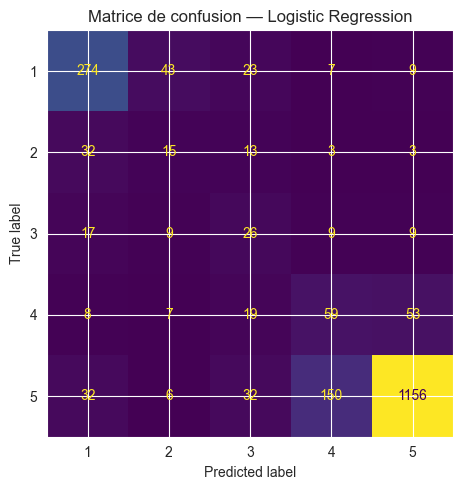

/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


=== Logistic Regression (test) ===
              precision    recall  f1-score   support

           1      0.755     0.770     0.762       356
           2      0.188     0.227     0.205        66
           3      0.230     0.371     0.284        70
           4      0.259     0.404     0.316       146
           5      0.940     0.840     0.887      1376

    accuracy                          0.760      2014
   macro avg      0.474     0.523     0.491      2014
weighted avg      0.808     0.760     0.780      2014



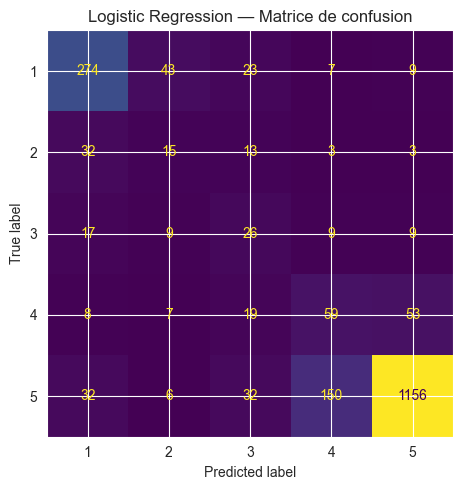


Top 20 — SATISFACTION (classe 5★)


,terme,poids
0,parfait,5.227452
1,top,4.443625
2,rapide,4.364449
3,merci,4.253403
4,recommande,3.594447
5,excellente,3.109300
6,super,3.085342
7,tres,2.923076
8,aussi,2.765525
9,magnifiques,2.761852



Top 20 — INSATISFACTION (classe 1★)


,terme,poids
0,fuir,4.999767
1,arnaque,4.475456
2,mauvaise,4.335466
3,ne,4.328019
4,aucune,3.897113
5,remboursement,3.450495
6,fuyez,3.177476
7,toujours,3.128806
8,repond,3.103626
9,refuse,3.043798



===== Naive Bayes =====
Accuracy: 0.7368
              precision    recall  f1-score   support

           1      0.741     0.772     0.757       356
           2      0.110     0.197     0.141        66
           3      0.210     0.371     0.268        70
           4      0.277     0.459     0.345       146
           5      0.952     0.802     0.870      1376

    accuracy                          0.737      2014
   macro avg      0.458     0.520     0.476      2014
weighted avg      0.812     0.737     0.767      2014



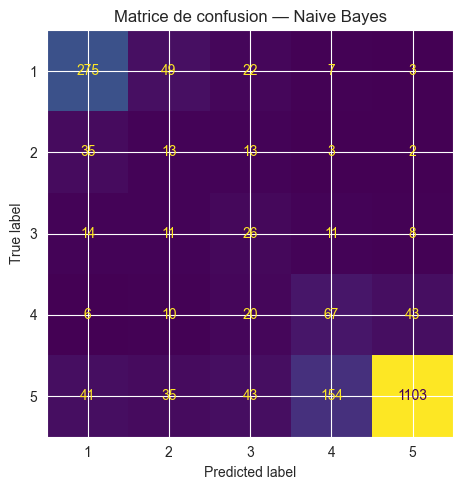


===== Linear SVM =====
Accuracy: 0.7607
              precision    recall  f1-score   support

           1      0.773     0.792     0.782       356
           2      0.171     0.182     0.176        66
           3      0.231     0.300     0.261        70
           4      0.239     0.370     0.290       146
           5      0.922     0.845     0.882      1376

    accuracy                          0.761      2014
   macro avg      0.467     0.498     0.478      2014
weighted avg      0.797     0.761     0.777      2014



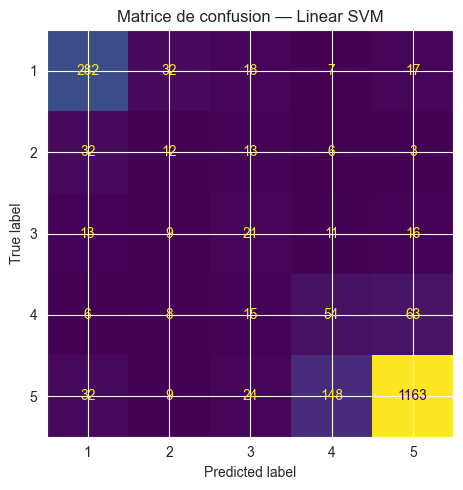


===== Random Forest =====
Accuracy: 0.8083
              precision    recall  f1-score   support

           1      0.689     0.840     0.757       356
           2      0.000     0.000     0.000        66
           3      0.000     0.000     0.000        70
           4      0.333     0.021     0.039       146
           5      0.844     0.964     0.900      1376

    accuracy                          0.808      2014
   macro avg      0.373     0.365     0.339      2014
weighted avg      0.723     0.808     0.751      2014



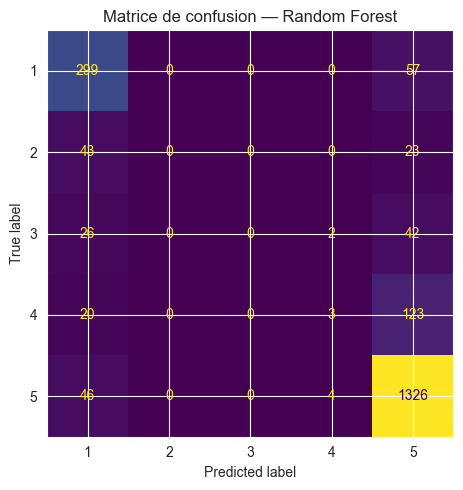


===== Gradient Boosting =====
Accuracy: 0.7036
              precision    recall  f1-score   support

           1      0.731     0.680     0.705       356
           2      0.096     0.182     0.126        66
           3      0.144     0.229     0.177        70
           4      0.205     0.390     0.269       146
           5      0.932     0.792     0.857      1376

    accuracy                          0.704      2014
   macro avg      0.422     0.455     0.426      2014
weighted avg      0.789     0.704     0.740      2014



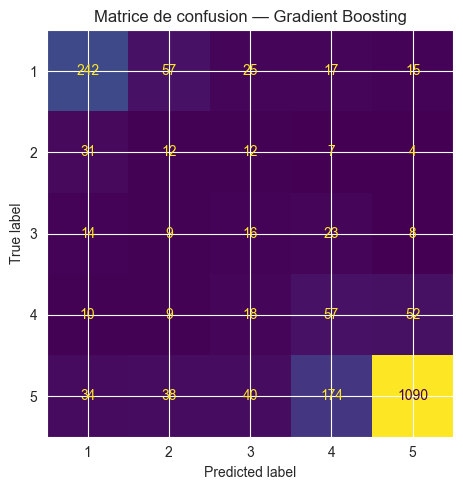

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
Logistic Regression,0.7597,0.4742,0.5225,0.4909,0.7803
Linear SVM,0.7607,0.4671,0.4978,0.4783,0.7766
Naive Bayes,0.7368,0.4579,0.5203,0.4763,0.7673
Gradient Boosting,0.7036,0.4217,0.4545,0.4265,0.7395
Random Forest,0.8083,0.3733,0.3648,0.3391,0.7514



Classement (par F1 macro) :
Logistic Regression    0.4909
Linear SVM             0.4783
Naive Bayes            0.4763
Gradient Boosting      0.4265
Random Forest          0.3391
Name: macro_f1, dtype: float64


In [20]:
#AJ Classification Abdoul

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# ---------- Helpers ----------
def to_dense(X):
    """Convertit en dense si nécessaire (utile pour RF/GB)."""
    return X.toarray() if hasattr(X, "toarray") else X

def evaluate_classif(y_true, y_pred, title="Model"):
    acc = accuracy_score(y_true, y_pred)
    print(f"\n===== {title} =====")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, digits=3, zero_division=0))
    labels = sorted(pd.Series(y_true).dropna().unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(5,5))
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"Matrice de confusion — {title}")
    plt.tight_layout()
    plt.show()

def extract_scores(report_dict):
    """Récupère l'essentiel d'un classification_report(output_dict=True)."""
    return {
        "accuracy": report_dict.get("accuracy", np.nan),
        "macro_precision": report_dict["macro avg"]["precision"],
        "macro_recall": report_dict["macro avg"]["recall"],
        "macro_f1": report_dict["macro avg"]["f1-score"],
        "weighted_f1": report_dict["weighted avg"]["f1-score"],
    }

# ---------- Vérifs minimales ----------
# On suppose qu'on a déjà :
# X_train_bal, y_train_bal, vect_bal, X_test, y_test
try:
    X_train_bal, y_train_bal, X_test_vect, y_test
except NameError as e:
    raise RuntimeError("Il manque des variables: assure-toi d'avoir rééquilibré et vectorisé le test.") from e

# Si X_test_vect n'existe pas encore, le re-créer:
#AJ pourquoi faire ça ??
if 'X_test_vect' not in globals():
    from pandas import Series
    X_test_vect = vect_bal.transform(Series(X_test).astype(str))

# Comme on a oversample, on met class_weight=None
results_classif = {}

# ---------- 1) Logistic Regression ----------
clf_logreg = LogisticRegression(
    max_iter=1000, solver="saga", n_jobs=-1,
    multi_class="auto", class_weight=None
)
clf_logreg.fit(X_train_bal, y_train_bal)
y_pred_logreg = clf_logreg.predict(X_test_vect)
results_classif["Logistic Regression"] = extract_scores(
    classification_report(y_test, y_pred_logreg, output_dict=True, zero_division=0)
)
evaluate_classif(y_test, y_pred_logreg, title="Logistic Regression")

#AJ Deuxieme Regression Logistique Abdoul
logreg = LogisticRegression(
    max_iter=800, solver="saga", n_jobs=-1,
    multi_class="auto", class_weight=None, C=1.0
)
logreg.fit(X_train_bal, y_train_bal)

y_pred_lr = logreg.predict(X_test_vect)
print("=== Logistic Regression (test) ===")
print(classification_report(y_test, y_pred_lr, digits=3))
plot_confusion(y_test, y_pred_lr, "Logistic Regression — Matrice de confusion")

# Mots les plus discriminants (1★ / 5★)
show_discriminative_terms_linear(logreg, vect_bal, y_train_bal, k=20)

#AJ Fin deuxieme regression logistique

# ---------- 2) Naive Bayes (Multinomial) ----------
clf_nb = MultinomialNB()
clf_nb.fit(X_train_bal, y_train_bal)
y_pred_nb = clf_nb.predict(X_test_vect)
results_classif["Naive Bayes"] = extract_scores(
    classification_report(y_test, y_pred_nb, output_dict=True, zero_division=0)
)
evaluate_classif(y_test, y_pred_nb, title="Naive Bayes")

# ---------- 3) Linear SVM (LinearSVC) ----------
clf_svm = LinearSVC(class_weight=None)
clf_svm.fit(X_train_bal, y_train_bal)
y_pred_svm = clf_svm.predict(X_test_vect)
results_classif["Linear SVM"] = extract_scores(
    classification_report(y_test, y_pred_svm, output_dict=True, zero_division=0)
)
evaluate_classif(y_test, y_pred_svm, title="Linear SVM")

# ---------- 4) Random Forest ----------
# Arbres: mieux en dense
X_train_bal_dense = to_dense(X_train_bal)
X_test_vect_dense = to_dense(X_test_vect)

clf_rf = RandomForestClassifier(
    n_estimators=300, random_state=42, n_jobs=-1,
    max_depth=None
)
clf_rf.fit(X_train_bal_dense, y_train_bal)
y_pred_rf = clf_rf.predict(X_test_vect_dense)
results_classif["Random Forest"] = extract_scores(
    classification_report(y_test, y_pred_rf, output_dict=True, zero_division=0)
)
evaluate_classif(y_test, y_pred_rf, title="Random Forest")

# ---------- 5) Gradient Boosting ----------
clf_gb = GradientBoostingClassifier(random_state=42)
clf_gb.fit(X_train_bal_dense, y_train_bal)
y_pred_gb = clf_gb.predict(X_test_vect_dense)
results_classif["Gradient Boosting"] = extract_scores(
    classification_report(y_test, y_pred_gb, output_dict=True, zero_division=0)
)
evaluate_classif(y_test, y_pred_gb, title="Gradient Boosting")

# ---------- Tableau récap ----------
results_df = (
    pd.DataFrame(results_classif)
      .T
      .sort_values("macro_f1", ascending=False)
      .round(4)
)
display(results_df)
print("\nClassement (par F1 macro) :")
print(results_df["macro_f1"].sort_values(ascending=False))



===== Logistic Regression =====
Accuracy: 0.7607
              precision    recall  f1-score   support

           1      0.758     0.772     0.765       356
           2      0.197     0.227     0.211        66
           3      0.228     0.371     0.283        70
           4      0.265     0.418     0.324       146
           5      0.938     0.839     0.886      1376

    accuracy                          0.761      2014
   macro avg      0.477     0.526     0.494      2014
weighted avg      0.809     0.761     0.781      2014



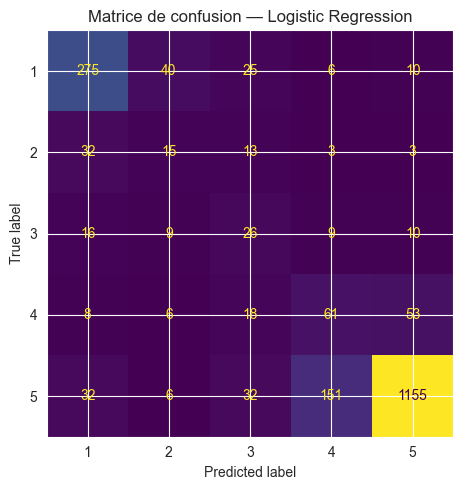


===== Naive Bayes =====
Accuracy: 0.7368
              precision    recall  f1-score   support

           1      0.741     0.772     0.757       356
           2      0.110     0.197     0.141        66
           3      0.210     0.371     0.268        70
           4      0.277     0.459     0.345       146
           5      0.952     0.802     0.870      1376

    accuracy                          0.737      2014
   macro avg      0.458     0.520     0.476      2014
weighted avg      0.812     0.737     0.767      2014



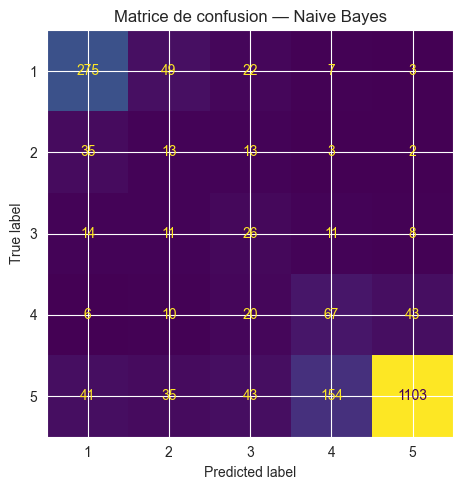


===== SVM =====
Accuracy: 0.7607
              precision    recall  f1-score   support

           1      0.773     0.792     0.782       356
           2      0.171     0.182     0.176        66
           3      0.231     0.300     0.261        70
           4      0.239     0.370     0.290       146
           5      0.922     0.845     0.882      1376

    accuracy                          0.761      2014
   macro avg      0.467     0.498     0.478      2014
weighted avg      0.797     0.761     0.777      2014



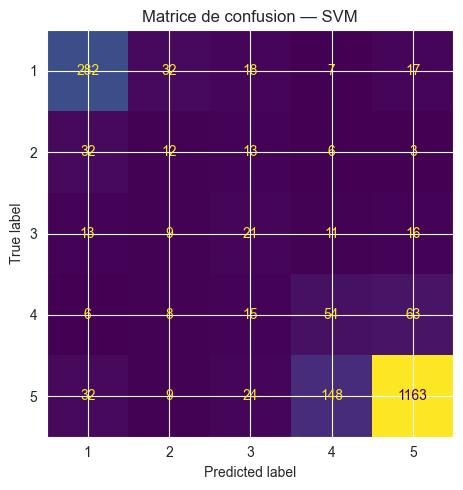


===== Random Forest =====
Accuracy: 0.8049
              precision    recall  f1-score   support

           1      0.671     0.837     0.745       356
           2      0.000     0.000     0.000        66
           3      1.000     0.014     0.028        70
           4      0.400     0.027     0.051       146
           5      0.845     0.958     0.898      1376

    accuracy                          0.805      2014
   macro avg      0.583     0.367     0.345      2014
weighted avg      0.760     0.805     0.750      2014



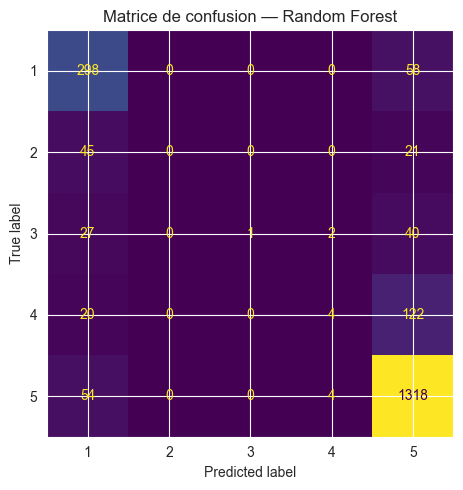


===== Gradient Boosting =====
Accuracy: 0.7036
              precision    recall  f1-score   support

           1      0.727     0.702     0.714       356
           2      0.096     0.167     0.122        66
           3      0.140     0.229     0.174        70
           4      0.210     0.404     0.276       146
           5      0.932     0.786     0.853      1376

    accuracy                          0.704      2014
   macro avg      0.421     0.457     0.428      2014
weighted avg      0.788     0.704     0.739      2014



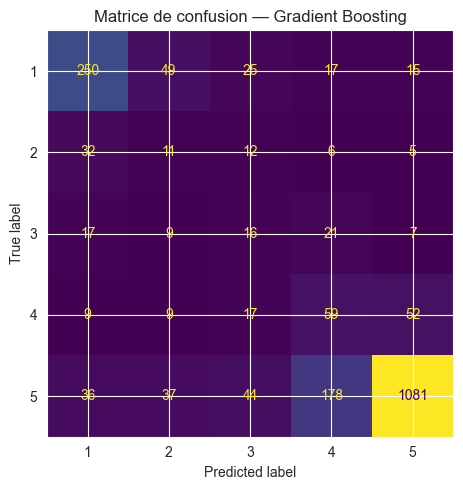

In [21]:
#AJ Classification Yekti
def evaluate_classif(y_true, y_pred, title="Model"):
    acc = accuracy_score(y_true, y_pred)
    print(f"\n===== {title} =====")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, digits=3, zero_division=0))
    labels = sorted(pd.Series(y_true).dropna().unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(5,5))
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"Matrice de confusion — {title}")
    plt.tight_layout()
    plt.show()

# Dictionnaire des résultats
results_classif = {}

# Logistic Regression
clf_logreg = LogisticRegression(max_iter=500, class_weight="balanced")
clf_logreg.fit(X_train_bal, y_train_bal)
y_pred_logreg = clf_logreg.predict(X_test_vect)
results_classif["Logistic Regression"] = classification_report(y_test, y_pred_logreg, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_logreg, title="Logistic Regression")

# Naive Bayes
clf_nb = MultinomialNB()
clf_nb.fit(X_train_bal, y_train_bal)
y_pred_nb = clf_nb.predict(X_test_vect)
results_classif["Naive Bayes"] = classification_report(y_test, y_pred_nb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_nb, title="Naive Bayes")

# SVM
clf_svm = LinearSVC(class_weight="balanced")
clf_svm.fit(X_train_bal, y_train_bal)
y_pred_svm = clf_svm.predict(X_test_vect)
results_classif["SVM"] = classification_report(y_test, y_pred_svm, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_svm, title="SVM")

# Random Forest
clf_rf = RandomForestClassifier(n_estimators=200, random_state=42)
clf_rf.fit(X_train_bal, y_train_bal)
y_pred_rf = clf_rf.predict(X_test_vect)
results_classif["Random Forest"] = classification_report(y_test, y_pred_rf, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_rf, title="Random Forest")

# Gradient Boosting
clf_gb = GradientBoostingClassifier()
clf_gb.fit(X_train_bal, y_train_bal)
y_pred_gb = clf_gb.predict(X_test_vect)
results_classif["Gradient Boosting"] = classification_report(y_test, y_pred_gb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_gb, title="Gradient Boosting")


In [22]:
#AJ Abdoul
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_selection import chi2

# Vérif des variables rééchantillonnées
for v in ["X_train_bal","y_train_bal","X_test_vect","y_test","vect_bal"]:
    assert v in globals(), f"Variable manquante: {v}"

def plot_confusion(y_true, y_pred, title):
    labels = sorted(pd.Series(y_true).dropna().unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(5,5))
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(title); plt.tight_layout(); plt.show()

def top_terms_from_linear(model, vectorizer, class_label, k=20):
    fn = np.array(vectorizer.get_feature_names_out())
    classes = model.classes_
    idx = list(classes).index(class_label)
    coefs = model.coef_[idx] if model.coef_.ndim > 1 else model.coef_
    order = np.argsort(coefs)[::-1][:k]
    return pd.DataFrame({"terme": fn[order], "poids": coefs[order]})

def show_discriminative_terms_linear(model, vectorizer, y_train, k=20):
    classes = sorted(np.unique(y_train))
    c1 = 1 if 1 in classes else classes[0]
    c5 = 5 if 5 in classes else classes[-1]
    print(f"\nTop {k} — SATISFACTION (classe {c5}★)")
    display(top_terms_from_linear(model, vectorizer, c5, k=k))
    print(f"\nTop {k} — INSATISFACTION (classe {c1}★)")
    display(top_terms_from_linear(model, vectorizer, c1, k=k))


In [23]:
#AJ XGBoost et LightGBM Yetki
# XGBoost
import xgboost as xgb
num_class = len(np.unique(y_train_bal))
xgb_clf = xgb.XGBClassifier(objective='multi:softmax', num_class=num_class, n_estimators=200, random_state=42)
xgb_clf.fit(X_train_bal, y_train_bal)
y_pred_xgb = xgb_clf.predict(X_test_vect.toarray())
results_classif["XGBoost"] = classification_report(y_test, y_pred_xgb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_xgb, title="XGBoost")

# LightGBM
import lightgbm as lgb
lgb_clf = lgb.LGBMClassifier(n_estimators=200, random_state=42)
lgb_clf.fit(X_train_bal, y_train_bal)
y_pred_lgb = lgb_clf.predict(X_test_vect.toarray())
results_classif["LightGBM"] = classification_report(y_test, y_pred_lgb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_lgb, title="LightGBM")

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <89AD948E-E564-3266-867D-7AF89D6488F0> /Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/li

In [15]:
#AJ XGBoost et LightGBM Abdoul
# XGBoost
try:
    from xgboost import XGBClassifier
    xgb = XGBClassifier(
        objective="multi:softprob", eval_metric="mlogloss",
        num_class=len(np.unique(y_train_bal)),
        n_estimators=300, max_depth=6, learning_rate=0.1,
        subsample=1.0, colsample_bytree=1.0,
        n_jobs=2, tree_method="hist", random_state=42
    )
    xgb.fit(X_train_bal, y_train_bal)
    y_pred_xgb = xgb.predict(X_test_vect)
    print("=== XGBoost (test) ===")
    print(classification_report(y_test, y_pred_xgb, digits=3))
    plot_confusion(y_test, y_pred_xgb, "XGBoost — Matrice de confusion")
except Exception as e:
    print("XGBoost indisponible :", e)

#AJ Deuxieme ?
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- Vérifs variables ---
for v in ["X_train_bal","y_train_bal","X_test_vect","y_test","vect_bal"]:
    assert v in globals(), f"Variable manquante: {v}"

# --- Mapping labels 1..5 -> 0..4 (XGB obligatoire) ---
classes_sorted = np.sort(np.unique(y_train_bal))
map_to_idx = {c:i for i,c in enumerate(classes_sorted)}   # ex: {1:0,2:1,3:2,4:3,5:4}
map_to_lbl = {i:c for c,i in map_to_idx.items()}          # inverse

y_train_xgb = np.array([map_to_idx[v] for v in y_train_bal])
y_test_xgb  = np.array([map_to_idx[v] for v in y_test])

# --- XGBoost config rapide (300 trees) ---
from xgboost import XGBClassifier
xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=len(classes_sorted),
    eval_metric="mlogloss",
    tree_method="hist",
    n_estimators=300, max_depth=6, learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0,
    random_state=42, n_jobs=2
)

# Fit + prédiction en indices 0..4
xgb.fit(X_train_bal, y_train_xgb)
y_pred_idx = xgb.predict(X_test_vect).astype(int)

# Remap vers labels originaux (1..5)
y_pred_xgb = np.array([map_to_lbl[i] for i in y_pred_idx])

print("=== XGBoost (test) ===")
print(classification_report(y_test, y_pred_xgb, digits=3))

cm = confusion_matrix(y_test, y_pred_xgb, labels=classes_sorted)
disp = ConfusionMatrixDisplay(cm, display_labels=classes_sorted)
disp.plot(values_format="d"); plt.title("XGBoost — Matrice de confusion"); plt.tight_layout(); plt.show()




# LightGBM
try:
    from lightgbm import LGBMClassifier
    from scipy import sparse
    X_train_in = X_train_bal if sparse.isspmatrix_csr(X_train_bal) else sparse.csr_matrix(X_train_bal)
    X_test_in  = X_test_vect if sparse.isspmatrix_csr(X_test_vect) else sparse.csr_matrix(X_test_vect)
    lgbm = LGBMClassifier(
        objective="multiclass", num_class=len(np.unique(y_train_bal)),
        n_estimators=300, num_leaves=31, learning_rate=0.1,
        subsample=1.0, colsample_bytree=1.0, n_jobs=2, random_state=42
    )
    lgbm.fit(X_train_in, y_train_bal)
    y_pred_lgb = lgbm.predict(X_test_in)
    print("=== LightGBM (test) ===")
    print(classification_report(y_test, y_pred_lgb, digits=3))
    plot_confusion(y_test, y_pred_lgb, "LightGBM — Matrice de confusion")
except Exception as e:
    print("LightGBM indisponible :", e)


#AJ Deuxieme ?


from lightgbm import LGBMClassifier
from scipy import sparse
import numpy as np

# Convertir en CSR si besoin
X_train_in = X_train_bal if sparse.isspmatrix_csr(X_train_bal) else sparse.csr_matrix(X_train_bal)
X_test_in  = X_test_vect if sparse.isspmatrix_csr(X_test_vect) else sparse.csr_matrix(X_test_vect)

lgbm = LGBMClassifier(
    objective="multiclass",
    num_class=len(np.unique(y_train_bal)),
    n_estimators=300, num_leaves=31, learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0,
    n_jobs=2,               # limite le parallélisme
    force_row_wise=True,    # évite la phase d’auto-choix
    random_state=42
)

lgbm.fit(X_train_in, y_train_bal)
y_pred_lgb = lgbm.predict(X_test_in)


from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("=== LightGBM (test) ===")
print(classification_report(y_test, y_pred_lgb, digits=3))

cm = confusion_matrix(y_test, y_pred_lgb, labels=np.sort(np.unique(y_train_bal)))
disp = ConfusionMatrixDisplay(cm, display_labels=np.sort(np.unique(y_train_bal)))
disp.plot(values_format="d"); plt.title("LightGBM — Matrice de confusion"); plt.tight_layout(); plt.show()

XGBoost indisponible : 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <89AD948E-E564-3266-867D-7AF89D6488F0> /Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libo


===== Logistic Regression =====
Accuracy: 0.7552
              precision    recall  f1-score   support

           1      0.790     0.772     0.781       356
           2      0.188     0.182     0.185        66
           3      0.149     0.186     0.166        70
           4      0.234     0.397     0.294       146
           5      0.918     0.845     0.880      1376

    accuracy                          0.755      2014
   macro avg      0.456     0.476     0.461      2014
weighted avg      0.795     0.755     0.773      2014



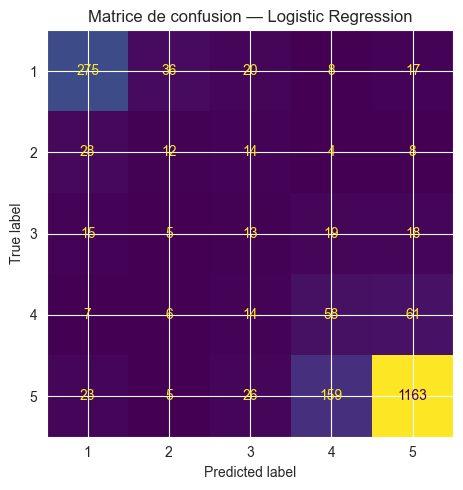


===== Naive Bayes =====
Accuracy: 0.7572
              precision    recall  f1-score   support

           1      0.732     0.792     0.761       356
           2      0.119     0.152     0.133        66
           3      0.185     0.243     0.210        70
           4      0.264     0.397     0.317       146
           5      0.939     0.842     0.888      1376

    accuracy                          0.757      2014
   macro avg      0.448     0.485     0.462      2014
weighted avg      0.801     0.757     0.776      2014



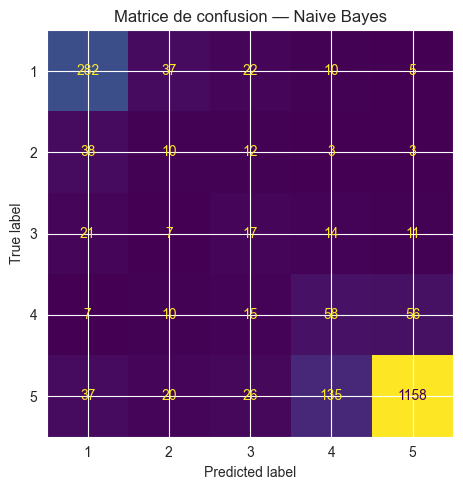


===== SVM =====
Accuracy: 0.7547
              precision    recall  f1-score   support

           1      0.755     0.770     0.762       356
           2      0.196     0.152     0.171        66
           3      0.130     0.100     0.113        70
           4      0.227     0.377     0.284       146
           5      0.900     0.853     0.876      1376

    accuracy                          0.755      2014
   macro avg      0.442     0.450     0.441      2014
weighted avg      0.776     0.755     0.763      2014



/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


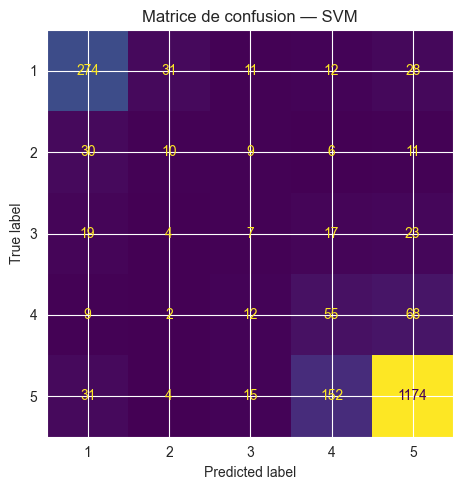


===== Random Forest =====
Accuracy: 0.8098
              precision    recall  f1-score   support

           1      0.690     0.817     0.748       356
           2      0.000     0.000     0.000        66
           3      0.000     0.000     0.000        70
           4      0.643     0.062     0.113       146
           5      0.843     0.967     0.901      1376

    accuracy                          0.810      2014
   macro avg      0.435     0.369     0.352      2014
weighted avg      0.745     0.810     0.756      2014



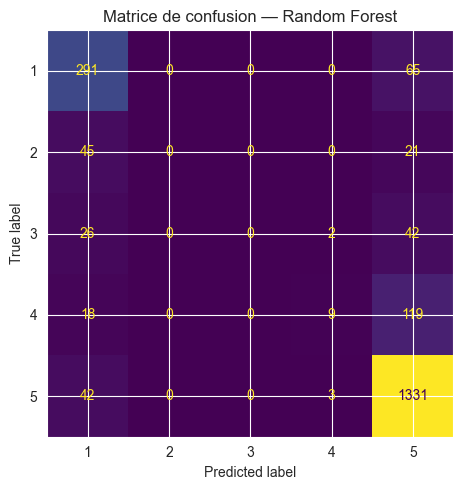


===== Gradient Boosting =====
Accuracy: 0.6832
              precision    recall  f1-score   support

           1      0.762     0.646     0.699       356
           2      0.111     0.258     0.155        66
           3      0.170     0.257     0.205        70
           4      0.195     0.438     0.270       146
           5      0.931     0.761     0.837      1376

    accuracy                          0.683      2014
   macro avg      0.434     0.472     0.433      2014
weighted avg      0.794     0.683     0.727      2014



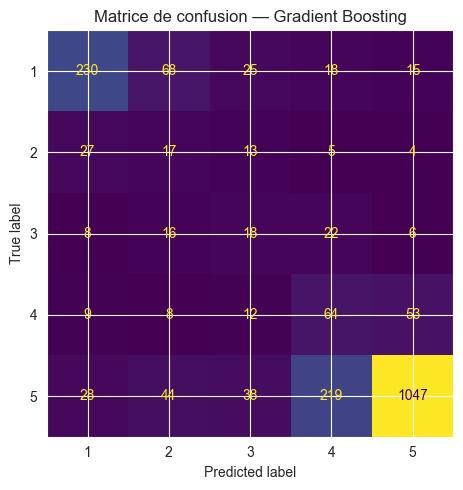

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <89AD948E-E564-3266-867D-7AF89D6488F0> /Users/eko/PyCharmMiscProject/.venv/lib/python3.9/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/li

In [14]:
def evaluate_classif(y_true, y_pred, title="Model"):
    acc = accuracy_score(y_true, y_pred)
    print(f"\n===== {title} =====")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, digits=3, zero_division=0))
    labels = sorted(pd.Series(y_true).dropna().unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(5,5))
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"Matrice de confusion — {title}")
    plt.tight_layout()
    plt.show()

# Dictionnaire des résultats
results_classif = {}

# Logistic Regression
clf_logreg = LogisticRegression(max_iter=500, class_weight="balanced")
clf_logreg.fit(X_train_bal, y_train_bal)
y_pred_logreg = clf_logreg.predict(X_test_vect)
results_classif["Logistic Regression"] = classification_report(y_test, y_pred_logreg, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_logreg, title="Logistic Regression")

# Naive Bayes
clf_nb = MultinomialNB()
clf_nb.fit(X_train_bal, y_train_bal)
y_pred_nb = clf_nb.predict(X_test_vect)
results_classif["Naive Bayes"] = classification_report(y_test, y_pred_nb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_nb, title="Naive Bayes")

# SVM
clf_svm = LinearSVC(class_weight="balanced")
clf_svm.fit(X_train_bal, y_train_bal)
y_pred_svm = clf_svm.predict(X_test_vect)
results_classif["SVM"] = classification_report(y_test, y_pred_svm, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_svm, title="SVM")

# Random Forest
clf_rf = RandomForestClassifier(n_estimators=200, random_state=42)
clf_rf.fit(X_train_bal, y_train_bal)
y_pred_rf = clf_rf.predict(X_test_vect)
results_classif["Random Forest"] = classification_report(y_test, y_pred_rf, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_rf, title="Random Forest")

# Gradient Boosting
clf_gb = GradientBoostingClassifier()
clf_gb.fit(X_train_bal, y_train_bal)
y_pred_gb = clf_gb.predict(X_test_vect)
results_classif["Gradient Boosting"] = classification_report(y_test, y_pred_gb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_gb, title="Gradient Boosting")

# XGBoost
import xgboost as xgb
num_class = len(np.unique(y_train_bal))
xgb_clf = xgb.XGBClassifier(objective='multi:softmax', num_class=num_class, n_estimators=200, random_state=42)
xgb_clf.fit(X_train_bal, y_train_bal)
y_pred_xgb = xgb_clf.predict(X_test_vect.toarray())
results_classif["XGBoost"] = classification_report(y_test, y_pred_xgb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_xgb, title="XGBoost")

# LightGBM
import lightgbm as lgb
lgb_clf = lgb.LGBMClassifier(n_estimators=200, random_state=42)
lgb_clf.fit(X_train_bal, y_train_bal)
y_pred_lgb = lgb_clf.predict(X_test_vect.toarray())
results_classif["LightGBM"] = classification_report(y_test, y_pred_lgb, output_dict=True, zero_division=0)
evaluate_classif(y_test, y_pred_lgb, title="LightGBM")

### Tableau récapitulatif

In [ ]:
df_classif_results = pd.DataFrame(results_classif).T
display(df_classif_results[["accuracy", "macro avg"]].style.background_gradient(cmap="Blues", axis=0))

### Visualisation

In [ ]:
metrics = ["accuracy", "f1-score"]
scores = {model: [res["accuracy"], res["macro avg"]["f1-score"]] for model, res in results_classif.items()}
df_scores = pd.DataFrame(scores, index=["Accuracy", "F1-macro"]).T

df_scores.plot(kind="bar", figsize=(10,6))
plt.title("Comparaison des modèles de classification")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge

results_reg = {}

# Régression Linéaire
reg_lin = LinearRegression()
reg_lin.fit(X_train_bal, y_train_bal)
y_pred_lin = reg_lin.predict(X_test_vect)
results_reg["Linear Regression"] = {
    "MSE": mean_squared_error(y_test, y_pred_lin),
    "MAE": mean_absolute_error(y_test, y_pred_lin),
    "R2": r2_score(y_test, y_pred_lin)
}

# Ridge Regression
reg_ridge = Ridge(alpha=1.0)
reg_ridge.fit(X_train_bal, y_train_bal)
y_pred_ridge = reg_ridge.predict(X_test_vect)
results_reg["Ridge Regression"] = {
    "MSE": mean_squared_error(y_test, y_pred_ridge),
    "MAE": mean_absolute_error(y_test, y_pred_ridge),
    "R2": r2_score(y_test, y_pred_ridge)
}

# Random Forest Regressor
reg_rf = RandomForestRegressor(n_estimators=200, random_state=42)
reg_rf.fit(X_train_bal, y_train_bal)
y_pred_rf = reg_rf.predict(X_test_vect)
results_reg["Random Forest Regressor"] = {
    "MSE": mean_squared_error(y_test, y_pred_rf),
    "MAE": mean_absolute_error(y_test, y_pred_rf),
    "R2": r2_score(y_test, y_pred_rf)
}

In [ ]:
results_reg = {}

# Régression Linéaire
reg_lin = LinearRegression()
reg_lin.fit(X_train_bal, y_train_bal)
y_pred_lin = reg_lin.predict(X_test_vect)
results_reg["Linear Regression"] = {
    "MSE": mean_squared_error(y_test, y_pred_lin),
    "MAE": mean_absolute_error(y_test, y_pred_lin),
    "R2": r2_score(y_test, y_pred_lin)
}

# Ridge Regression
reg_ridge = Ridge(alpha=1.0)
reg_ridge.fit(X_train_bal, y_train_bal)
y_pred_ridge = reg_ridge.predict(X_test_vect)
results_reg["Ridge Regression"] = {
    "MSE": mean_squared_error(y_test, y_pred_ridge),
    "MAE": mean_absolute_error(y_test, y_pred_ridge),
    "R2": r2_score(y_test, y_pred_ridge)
}

# Random Forest Regressor
reg_rf = RandomForestRegressor(n_estimators=200, random_state=42)
reg_rf.fit(X_train_bal, y_train_bal)
y_pred_rf = reg_rf.predict(X_test_vect)
results_reg["Random Forest Regressor"] = {
    "MSE": mean_squared_error(y_test, y_pred_rf),
    "MAE": mean_absolute_error(y_test, y_pred_rf),
    "R2": r2_score(y_test, y_pred_rf)
}

### Tableau récapitulatif

In [ ]:
df_reg_results = pd.DataFrame(results_reg).T
display(df_reg_results.style.background_gradient(cmap="Blues", axis=0))

### Visualisation (scatter plots)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

axes[0].scatter(y_test, y_pred_lin, alpha=0.3, label="Régression Linéaire")
axes[0].scatter(y_test, y_pred_rf, alpha=0.3, label="Random Forest")
axes[0].plot([1,5], [1,5], "r--")
axes[0].set_title("Régressions Linéaire & RF")
axes[0].set_xlabel("Vraies notes")
axes[0].set_ylabel("Prédictions")
axes[0].legend()

axes[1].scatter(y_test, y_pred_ridge, alpha=0.3, label="Ridge Regression")
axes[1].scatter(y_test, y_pred_rf, alpha=0.3, label="Random Forest")
axes[1].plot([1,5], [1,5], "r--")
axes[1].set_title("Ridge & RF")
axes[1].set_xlabel("Vraies notes")
axes[1].set_ylabel("Prédictions")
axes[1].legend()

plt.suptitle("Comparaison des modèles de régression")
plt.show()

## 4) Comparaison TF-IDF vs Embeddings

Nous comparons maintenant les représentations TF-IDF avec des embeddings sémantiques (`SentenceTransformer`).

Cette étape permet de vérifier si les embeddings pré-entraînés apportent un gain de performance significatif.


In [ ]:
from sentence_transformers import SentenceTransformer

model_name = "paraphrase-multilingual-MiniLM-L12-v2"
sbert = SentenceTransformer(model_name)

print("Encodage SBERT en cours...")
X_train_emb = sbert.encode(X_train.astype(str).tolist(), show_progress_bar=True)
X_test_emb  = sbert.encode(X_test.astype(str).tolist(), show_progress_bar=True)

# Logistic Regression sur embeddings
clf_emb_log = LogisticRegression(max_iter=500)
clf_emb_log.fit(X_train_emb, y_train)
y_pred_emb = clf_emb_log.predict(X_test_emb)
evaluate_classif(y_test, y_pred_emb, title="LogReg + Embeddings (SBERT)")

# Random Forest sur embeddings
clf_emb_rf = RandomForestClassifier(n_estimators=200, random_state=42)
clf_emb_rf.fit(X_train_emb, y_train)
y_pred_emb_rf = clf_emb_rf.predict(X_test_emb)
evaluate_classif(y_test, y_pred_emb_rf, title="Random Forest + Embeddings (SBERT)")


## 5) Interprétabilité des modèles (Objectif 2)

Au-delà de la performance prédictive, il est essentiel de comprendre **pourquoi** les modèles prennent certaines décisions.  
Cela permet de générer des insights actionnables pour l’entreprise (ex : quels mots sont les plus liés aux avis négatifs ou positifs ?).

Nous présentons trois approches complémentaires :

1. **Coefficients des modèles linéaires (LogReg, SVM)**  
   - Permet d’identifier directement les mots les plus discriminants par classe.  
   - Utile pour interpréter les relations globales.  

2. **SHAP (SHapley Additive exPlanations)**  
   - Importance globale des tokens pour un modèle donné.  
   - Explication locale : contribution de chaque mot dans un avis particulier.  

3. **LIME (Local Interpretable Model-agnostic Explanations)**  
   - Explication d’un avis individuel en identifiant les mots qui influencent le plus la prédiction.  

L’objectif est de relier la modélisation à une compréhension métier :  
- Quelles expressions déclenchent une note basse (1–2) ?  
- Quelles formulations sont associées aux avis très positifs (5) ?  


### a) Coefficients logistiques & SVM

Pour les modèles linéaires (régression logistique, SVM), les coefficients associés aux tokens peuvent être directement interprétés.  
Ils permettent d’identifier les mots les plus indicatifs pour chaque classe (1–5 étoiles).  

Nous extrayons et visualisons le Top-10 mots les plus discriminants par classe.  


In [ ]:
# Fonction utilitaire pour extraire les top features par classe
def show_top_features(vectorizer, clf, n=10):
    feature_names = np.array(vectorizer.get_feature_names_out())
    if hasattr(clf, "coef_"):
        for i, class_label in enumerate(clf.classes_):
            topn = np.argsort(clf.coef_[i])[-n:]
            print(f"\nClasse {class_label} - Top {n} mots indicatifs :")
            print(", ".join(feature_names[topn]))

# Logistic Regression
show_top_features(vectorizer, clf, n=10)

# SVM
show_top_features(vectorizer_svm, clf_svm, n=10)


### b) SHAP

SHAP (SHapley Additive exPlanations) permet d’expliquer les prédictions en attribuant un poids d’importance à chaque token.  
Deux niveaux d’interprétation sont possibles :  
- Importance globale : quels mots influencent le plus le modèle sur l’ensemble des prédictions.  
- Importance locale : explication de la prédiction pour un avis particulier.  


In [ ]:
import shap

# Préparation des vecteurs TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_df=0.9, sublinear_tf=True)
X_train_vect = vectorizer.fit_transform(X_train.astype(str))
X_test_vect  = vectorizer.transform(X_test.astype(str))

feature_names = vectorizer.get_feature_names_out()

# Dictionnaire des modèles entraînés
models = {
    "Logistic Regression": clf_logreg,
    "SVM": clf_svm,
    "Random Forest": clf_rf,
    "Gradient Boosting": clf_gb,
    "XGBoost": xgb_clf,
    "LightGBM": lgb_clf,
    "Linear Regression": reg_lin,
    "Ridge Regression": reg_ridge,
    "Random Forest Regressor": reg_rf
}

# Fonction d'explication SHAP
def shap_explain_model(model, X_train_vect, X_test_vect, feature_names, model_name="Modèle", max_display=10):
    # Conversion dense : sert à convertir les matrices sparse (sciPy) en matrices denses (numpy array) si le modèle ou SHAP en a besoin.
    if hasattr(X_train_vect, "toarray"):
        X_train_arr, X_test_arr = X_train_vect.toarray(), X_test_vect.toarray()
    else:
        X_train_arr, X_test_arr = X_train_vect, X_test_vect

    # Choix de l'explainer selon le modèle
    if "LogisticRegression" in str(type(model)) or "LinearSVC" in str(type(model)):
        explainer = shap.LinearExplainer(model, X_train_arr, feature_dependence="independent")
    elif "Forest" in str(type(model)) or "GradientBoosting" in str(type(model)):
        explainer = shap.TreeExplainer(model)
    elif "Ridge" in str(type(model)) or "LinearRegression" in str(type(model)):
        explainer = shap.LinearExplainer(model, X_train_arr)
    else:
        explainer = shap.KernelExplainer(model.predict, X_train_arr[:200])  # lent mais générique

    # Calcul sur un sous-échantillon
    shap_values = explainer(X_test_arr[:200])
    print(f"\n{model_name}")

    # Importance globale (top features)
    shap.summary_plot(shap_values, X_test_arr[:200], feature_names=feature_names, show=True, max_display=max_display)

    # Exemple d’explication locale (premier avis du test set)
    shap.plots.waterfall(shap_values[0], max_display=max_display)

# Boucle sur tous les modèles
for name, model in models.items():
    try:
        shap_explain_model(model, X_train_vect, X_test_vect, feature_names, model_name=name)
    except Exception as e:
        print(f"SHAP pas applicable pour {name}: {e}")


*NB:* Pourquoi faire une Conversion dense?

Quand nous vectorisons les textes avec TF-IDF ou CountVectorizer, nous obtenons une sparse matrix (scipy.sparse.csr_matrix) → mémoire optimisée car la plupart des valeurs sont 0.

Certains explainers SHAP (LinearExplainer, KernelExplainer) ne supportent pas directement ce format sparse → il faut donc le convertir en .toarray().

Par contre, si les données sont déjà en array (par exemple après un fit_resample de SMOTE ou un modèle qui a déjà converti), nous les gardons telles quelles pour éviter une conversion inutile.

Donc ici, le "if hasattr(..., "toarray")" est juste une sécurité générique :
- Si c’est un sparse matrix → conversion dense.
- Si c’est déjà dense → pas de conversion.

## 9) LIME

LIME (Local Interpretable Model-agnostic Explanations) permet d’interpréter localement une prédiction.  
L’approche consiste à perturber légèrement le texte et à mesurer l’influence de chaque mot sur la décision finale.  

Nous illustrons ci-dessous une explication locale pour un avis de test.  


In [ ]:
from lime.lime_text import LimeTextExplainer

# Définition de la classe pour LIME
class_names = [str(c) for c in sorted(y_train.unique())]
explainer_lime = LimeTextExplainer(class_names=class_names)

# Exemple sur un avis
idx = 10
exp = explainer_lime.explain_instance(
    X_test.iloc[idx],
    pipe_logreg.predict_proba,
    num_features=10
)

print("Texte :", X_test.iloc[idx])
exp.show_in_notebook(text=True)


### Résumé des approches

- Les coefficients LogReg et SVM confirment que certains mots sont très fortement associés aux notes extrêmes  
  (ex : "parfait", "excellent" pour 5 étoiles vs "retard", "cassé", "remboursement" pour 1 étoile).  

- Les valeurs SHAP donnent une vue plus fine de l’importance des tokens, à la fois globale et locale.  
  Cela permet d’expliquer pourquoi un avis particulier a été classé dans une catégorie.  

- LIME offre une explication lisible par les non-techniciens, en montrant quels mots d’un avis influencent le plus la prédiction.  

En combinant ces trois approches, nous disposons à la fois d’une vision globale et locale des modèles,
ce qui est crucial pour la confiance et l’exploitation métier.


## 5) Approche Deep Learning

Les modèles classiques (régression logistique, SVM, Random Forest, etc.) exploitent des représentations TF-IDF.  
Ces représentations ignorent le contexte et l’ordre des mots : par exemple, “pas du tout satisfait” et “très satisfait” partagent le mot “satisfait” mais expriment des polarités opposées.  

Le Deep Learning permet de mieux capturer ces nuances linguistiques grâce à :
- des RNN (LSTM / GRU) qui apprennent les dépendances séquentielles,  
- des Transformers (CamemBERT), modèles pré-entraînés en français, qui comprennent mieux le contexte global.

Nous testons les modéles suivants:
- **RNN (LSTM/GRU)**  
  - Encode les avis comme séquences de tokens.  
  - Capable de capturer l’ordre et la dépendance locale des mots.  
  - Limité face au déséquilibre des classes rares.  

- **CamemBERT (fine-tuning)**  
  - Modèle Transformer pré-entraîné spécifiquement pour le français.  
  - Fine-tuning pour classification 1–5 étoiles.  
  - Attendu comme meilleur modèle sur ce type de tâche.  

### Contraintes
- Temps d’entraînement beaucoup plus long,  
- Besoin de GPU pour un fine-tuning efficace,  
- Difficulté d’interprétation (modèle boîte noire).  

### Métriques utilisées
- Accuracy  
- F1-score macro  
- Matrice de confusion  
- Courbes d’apprentissage (loss / accuracy par epoch)  

### Attentes
- Les **RNN** devraient apporter une amélioration modérée par rapport aux modèles TF-IDF.  
- Le **CamemBERT** est attendu comme le modèle le plus performant, surtout sur les classes rares (2–3–4).  

### Rééquilibrage et Deep Learning
Le rééquilibrage (SMOTE ou oversampling) peut être appliqué en amont, mais pour le Deep Learning on préfère souvent :  
- **class_weight** pendant l’entraînement,  
- ou **oversampling des séquences** (répétition des avis minoritaires).  

Nous conservons la logique précédente :  
- **Train rééquilibré** (SMOTE ou oversampling),  
- **Validation & Test inchangés** (jamais rééquilibrés pour garder une évaluation réaliste).  

Nous comparons donc :  
- LSTM **avec et sans rééquilibrage**,  
- CamemBERT **avec class weights** vs **avec oversampling**.  


*NB: Code simple vs Code optimisé pour chaque modéle : choix du meilleur compromis*

Nous pouvons implémenter deux versions des modèles Deep Learning :

- **Version simple**  
  - Paramètres par défaut (embedding_dim réduit, epochs limités, peu de régularisation).  
  - Objectif : valider rapidement le bon fonctionnement du pipeline.  
  - Limites : sous-apprentissage, performances modestes.

- **Version optimisée**  
  - Ajustement des hyperparamètres (taille d’embedding, hidden_size du LSTM, batch_size, learning_rate).  
  - Ajout de techniques de régularisation (dropout, early stopping).  
  - Entraînement prolongé avec GPU.  
  - Objectif : tirer pleinement parti des modèles.  

**Pourquoi avons nous choisi l’optimisée ?**  
Parce que l’objectif de notre étude est d’obtenir des performances compétitives, surtout sur les classes rares (2–3–4).  
La version simple reste utile pour du prototypage rapide, mais les résultats exploitables (pour comparaison avec TF-IDF et pour les livrables métiers) viennent de la version optimisée.  


## a) Modéle LSTM

### Etapes d’entraînement

1. Préparation des données  
   - Tokenisation des avis (séquences de mots → indices).  
   - Padding pour obtenir des séquences de même longueur.  
   - Création de *DataLoader* PyTorch (train/val/test).  

2. Construction du modèle  
   - Embedding layer : transforme chaque mot en vecteur dense.  
   - LSTM : capture l’ordre et les dépendances séquentielles entre les mots.  
   - Couche fully-connected (FC) : projection finale sur 5 classes (1–5 étoiles).  

3. Entraînement  
   - Fonction de perte : `CrossEntropyLoss`.  
   - Optimiseur : Adam.  
   - Suivi du `train_loss` et `val_loss` à chaque epoch.  

4. Évaluation  
   - Prédictions sur le jeu test.  
   - Calcul des métriques (accuracy, macro-F1).  
   - Visualisation des matrices de confusion.  

Le LSTM capture mieux le contexte que TF-IDF mais reste limité sur les classes rares.  


## b) Modéle CamemBERT

### Etapes d’entraînement

1. Préparation des données
   - Tokenisation via `CamembertTokenizer` (WordPiece subwords).  
   - Conversion en tenseurs (input_ids, attention_mask).  
   - Construction des datasets HuggingFace (train/val/test).  

2. Construction du modèle
   - Utilisation de `CamembertForSequenceClassification`.  
   - Poids pré-entraînés sur de grands corpus en français.  
   - Ajout d’une tête de classification adaptée à notre tâche (5 classes).  

3. Entraînement (fine-tuning)  
   - Optimiseur AdamW + scheduler d’apprentissage.  
   - Early stopping sur la *val_loss*.  
   - Suivi de l’accuracy et du F1-macro.  

4. Évaluation  
   - Prédictions sur test.  
   - Matrices de confusion.  
   - Comparaison des performances avec LSTM et modèles TF-IDF.  

Le CamemBERT capte le contexte global et surpasse en général les modèles LSTM/TF-IDF, surtout sur les classes rares.  

## **Objectif 3 — Approches complémentaires hors classification et régression**

Afin d’aller au-delà de la prédiction directe des notes, nous explorons des méthodes complémentaires :  
- Clustering non supervisé (KMeans + TF-IDF embeddings).  
- Topic Modeling (LDA) → extraction de thèmes (ex : livraison, SAV, qualité produit).  
- Analyse temporelle → évolution des notes dans le temps.  
- Détection d’émotions → cartographie des émotions dominantes par note.